In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
!pip install -q streamlit
import os
import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn
import joblib
import streamlit

print("Python       :", sys.version.split()[0])
print("Pandas       :", pd.__version__)
print("NumPy        :", np.__version__)
print("Matplotlib   :", matplotlib.__version__)
print("Seaborn      :", sns.__version__)
print("ScikitLearn  :", sklearn.__version__)
print("Joblib       :", joblib.__version__)
print("Streamlit    :", streamlit.__version__)

Python       : 3.13.16
Pandas       : 2.2.3
NumPy        : 2.1.3
Matplotlib   : 3.10.0
Seaborn      : 0.13.2
ScikitLearn  : 1.6.1
Joblib       : 1.6.0
Streamlit    : 1.66.1


***DATASET FOLDER STRUCTURE***

In [8]:



PROJECT = "/content/drive/MyDrive/PriceSense"

folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "src",
    "models",
    "app",
    "reports/figures",
]

for folder in folders:
    path = f"{PROJECT}/{folder}"
    if os.path.exists(path):
        print("ALREADY EXIST :", folder)
    else:
        os.makedirs(path)
        print("cREATING FOLDER  :", folder)

open(f"{PROJECT}/src/__init__.py", "a").close()

ALREADY EXIST : data/raw
ALREADY EXIST : data/processed
ALREADY EXIST : notebooks
ALREADY EXIST : src
ALREADY EXIST : models
ALREADY EXIST : app
ALREADY EXIST : reports/figures


***CHECK DATASET EXISTANCE***

In [9]:
CSV_PATH = f"{PROJECT}/data/raw/pakwheels.csv"

if os.path.exists(CSV_PATH):
    size_mb = os.path.getsize(CSV_PATH) / (1024 * 1024)
    print(f"Dataset exist ({size_mb:.2f} MB):", CSV_PATH)
else:
    from google.colab import files
    print("select a file")
    uploaded = files.upload()

    file_name = list(uploaded.keys())[0]
    with open(CSV_PATH, "wb") as f:
        f.write(uploaded[file_name])

    print("Dataset save:", CSV_PATH)

Dataset exist (54.48 MB): /content/drive/MyDrive/PriceSense/data/raw/pakwheels.csv


***LOAD AND CHECK DATASET***

In [10]:

CSV_PATH = f"{PROJECT}/data/raw/pakwheels.csv"

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {CSV_PATH}"
    )

df = pd.read_csv(CSV_PATH, low_memory=False)

print("Dataset loaded successfully!")
print("-" * 50)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset loaded successfully!
--------------------------------------------------
Number of rows: 89956
Number of columns: 17

Column names:
['Unnamed: 0', 'ad_url', 'title', 'location', 'model_year', 'price', 'mileage', 'engine_type', 'transmission', 'registered_in', 'color', 'assembly', 'engine_capacity', 'body_type', 'ad_last_updated', 'car_features', 'description']

First 5 rows:


,Unnamed: 0,ad_url,title,location,model_year,price,mileage,engine_type,transmission,registered_in,color,assembly,engine_capacity,body_type,ad_last_updated,car_features,description
0,0,https://www.pakwheels.com/used-cars/honda-civi...,Honda Civic VTi Oriel Prosmatec 1.8 i-VTEC 2007,Islamabad Islamabad,2007.0,PKR 16.5 lacs,"100,000 km",Petrol,Automatic,Lahore,Grey,Imported Cars,1800 cc,Sedan,"Oct 09, 2022",ABS\nAM/FM Radio\nAir Bags\nAir Conditioning\n...,2007 model full option Chat piller geniune or ...
1,1,https://www.pakwheels.com/used-cars/suzuki-meh...,Suzuki Mehran VX Euro II 2012,"Eden Gardens, Faisalabad Punjab",2012.0,PKR 7 lacs,"100,000 km",Petrol,Manual,Faisalabad,Grey,Imported Cars,800 cc,Hatchback,"Oct 09, 2022",AM/FM Radio\nCD Player\nImmobilizer Key,"Very smooth drive,70% in orignal paint rest of..."
2,2,https://www.pakwheels.com/used-cars/honda-civi...,Honda Civic EX 1995,"Bostan Road, Rawalpindi Punjab",1995.0,PKR 7.6 lacs,999 km,Petrol,Manual,Lahore,Black,Imported Cars,1500 cc,Sedan,"Oct 09, 2022",AM/FM Radio\nAir Conditioning\nAlloy Rims\nCas...,1600cc Engine installed Alloy RimsAir Conditio...
3,3,https://www.pakwheels.com/used-cars/toyota-for...,Toyota Fortuner 2.7 VVTi 2013,"Kallar Kahar Road, Chakwal Punjab",2013.0,PKR 70 lacs,"94,000 km",Petrol,Automatic,Lahore,Black,Imported Cars,2700 cc,SUV,"Oct 09, 2022",ABS\nAM/FM Radio\nAir Bags\nAir Conditioning\n...,Inside out fully original. Original return fil...
4,4,https://www.pakwheels.com/used-cars/suzuki-meh...,Suzuki Mehran VX Euro II 2015,Muzaffar Gargh Punjab,2015.0,PKR 8 lacs,"86,000 km",Petrol,Manual,Multan,Grey,Imported Cars,796 cc,Hatchback,"Oct 09, 2022",AM/FM Radio\nCD Player\nImmobilizer Key,gari total genion hy.chill a.c.new tires.no wo...



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89956 entries, 0 to 89955
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       89956 non-null  int64  
 1   ad_url           89956 non-null  object 
 2   title            89956 non-null  object 
 3   location         89954 non-null  object 
 4   model_year       87449 non-null  float64
 5   price            89954 non-null  object 
 6   mileage          89954 non-null  object 
 7   engine_type      89001 non-null  object 
 8   transmission     89954 non-null  object 
 9   registered_in    89954 non-null  object 
 10  color            88093 non-null  object 
 11  assembly         89956 non-null  object 
 12  engine_capacity  89954 non-null  object 
 13  body_type        81407 non-null  object 
 14  ad_last_updated  89954 non-null  object 
 15  car_features     83435 non-null  object 
 16  description      89954 non-null  obj

,0
body_type,8549
car_features,6521
model_year,2507
color,1863
engine_type,955
ad_last_updated,2
mileage,2
price,2
location,2
description,2



Duplicate rows: 0


***Inspect important columns***

In [11]:


columns_to_check = [
    "price",
    "mileage",
    "model_year",
    "engine_capacity",
    "title",
    "location",
    "assembly"
]

print("Sample values from important columns:\n")

for column in columns_to_check:
    print(f"\n--- {column} ---")
    print(df[column].dropna().astype(str).head(10).to_list())

print("\nPrice format examples:")
display(df["price"].value_counts().head(15).rename("count").to_frame())

print("\nModel year range:")
print(df["model_year"].describe())

print("\nMissing values in target price:", df["price"].isna().sum())


Sample values from important columns:


--- price ---
['PKR 16.5 lacs', 'PKR 7 lacs', 'PKR 7.6 lacs', 'PKR 70 lacs', 'PKR 8 lacs', 'PKR 25.5 lacs', 'PKR 13 lacs', 'PKR 36 lacs', 'PKR 36.6 lacs', 'PKR 51.75 lacs']

--- mileage ---
['100,000 km', '100,000 km', '999 km', '94,000 km', '86,000 km', '85,000 km', '97,000 km', '56,000 km', '28,000 km', '14,500 km']

--- model_year ---
['2007.0', '2012.0', '1995.0', '2013.0', '2015.0', '2012.0', '2011.0', '2018.0', '2018.0', '2020.0']

--- engine_capacity ---
['1800 cc', '800 cc', '1500 cc', '2700 cc', '796 cc', '1600 cc', '660 cc', '1500 cc', '1600 cc', '1000 cc']

--- title ---
['Honda Civic VTi Oriel Prosmatec 1.8 i-VTEC 2007', 'Suzuki Mehran VX Euro II 2012', 'Honda Civic EX 1995', 'Toyota Fortuner 2.7 VVTi 2013', 'Suzuki Mehran VX Euro II 2015', 'Toyota Corolla Altis SR Cruisetronic 1.6 2012', 'Suzuki MR Wagon WIT LIMITED 2011', 'Honda BR-V i-VTEC S 2018', 'Toyota Corolla Altis X Automatic 1.6 Special Edition 2018', 'Toyota Raize 2020']

-

,count
price,
Call for price,1405
PKR 22 lacs,781
PKR 13.5 lacs,751
PKR 21 lacs,745
PKR 12.5 lacs,734
PKR 7.5 lacs,724
PKR 6.5 lacs,715
PKR 18.5 lacs,714
PKR 22.5 lacs,692



Model year range:
count    87449.000000
mean      2012.861576
std          7.669485
min       1990.000000
25%       2007.000000
50%       2015.000000
75%       2019.000000
max       2022.000000
Name: model_year, dtype: float64

Missing values in target price: 2


***DATA CLEANING***



In [12]:
import argparse
import re
import sys
from pathlib import Path



REFERENCE_YEAR = 2022

REQUIRED_COLUMNS = [
    "price",
    "mileage",
    "engine_capacity",
    "model_year",
]

ID_COLUMNS = ["Unnamed: 0", "ad_url"]

TEXT_COLUMNS = [
    "location",
    "engine_type",
    "transmission",
    "registered_in",
    "color",
    "assembly",
    "body_type",
]

cleaning_log = []


def log_step(step, before, after, note=""):
    cleaning_log.append({
        "step": step,
        "rows_before": before,
        "rows_after": after,
        "rows_removed": before - after,
        "note": note,
    })

    print(
        f"[{step}] {before:,} -> {after:,} rows "
        f"({before - after:,} removed)"
    )


def default_project_path():
    colab_path = Path("/content/drive/MyDrive/PriceSense")

    if colab_path.exists():
        return colab_path

    try:
        return Path(__file__).resolve().parent.parent
    except NameError:
        return Path.cwd()


def load_raw(raw_path):
    if not raw_path.exists():
        raise FileNotFoundError(
            f"Raw dataset not found: {raw_path}"
        )

    last_error = None

    for encoding in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            df = pd.read_csv(
                raw_path,
                encoding=encoding,
                low_memory=False
            )

            print(
                f"Raw dataset loaded using {encoding}: "
                f"{df.shape[0]:,} rows x {df.shape[1]} columns"
            )

            return df

        except UnicodeDecodeError as err:
            last_error = err

    raise ValueError(
        f"Could not read CSV using supported encodings: {last_error}"
    )


def check_columns(df):
    missing = [
        col for col in REQUIRED_COLUMNS
        if col not in df.columns
    ]

    if missing:
        raise KeyError(
            f"Required columns are missing: {missing}"
        )


def convert_price_to_pkr(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower().replace(",", "")

    if not text or "call for price" in text:
        return np.nan

    text = re.sub(r"\bpkr\b", "", text).strip()

    match = re.search(
        r"^\s*(\d+(?:\.\d+)?)\s*(.*?)\s*$",
        text
    )

    if not match:
        return np.nan

    amount = float(match.group(1))
    unit = match.group(2).strip()

    if re.search(r"\b(crore|crores|cr)\b", unit):
        return amount * 10_000_000

    if re.search(r"\b(lac|lacs|lakh|lakhs)\b", unit):
        return amount * 100_000

    if unit == "":
        return amount

    return np.nan

def parse_numeric_columns(df):
    df = df.copy()

    df["price_pkr"] = df["price"].apply(
        convert_price_to_pkr
    )

    df["mileage_km"] = pd.to_numeric(
        df["mileage"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.replace(r"(?i)\s*km\s*", "", regex=True)
        .str.strip(),
        errors="coerce"
    )

    df["engine_capacity_cc"] = pd.to_numeric(
        df["engine_capacity"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.replace(r"(?i)\s*cc\s*", "", regex=True)
        .str.strip(),
        errors="coerce"
    )
    cc = df["engine_capacity_cc"]

    bad_cc = cc.notna() & ~cc.between(500, 6000)

    print(
        "Invalid engine capacities changed to missing:",
        int(bad_cc.sum())
    )

    df.loc[bad_cc, "engine_capacity_cc"] = np.nan

    bad_mileage = (
        df["mileage_km"].notna()
        & (df["mileage_km"] <= 0)
    )

    print(
        "Non-positive mileage changed to missing:",
        int(bad_mileage.sum())
    )

    df.loc[bad_mileage, "mileage_km"] = np.nan


    for col in TEXT_COLUMNS:
        if col in df.columns:
            df[col] = (
                df[col]
                .astype("string")
                .str.strip()
                .replace("", pd.NA)
            )

    print(
        f"Usable prices: {df['price_pkr'].notna().sum():,}"
    )
    print(
        f"Usable mileage values: {df['mileage_km'].notna().sum():,}"
    )
    print(
        "Usable engine capacities:",
        f"{df['engine_capacity_cc'].notna().sum():,}"
    )

    return df


def add_model_year_and_age(df):
    df = df.copy()

    year = pd.to_numeric(
        df["model_year"],
        errors="coerce"
    )

    bad_year = (
        year.notna()
        & ~year.between(1990, REFERENCE_YEAR + 1)
    )

    print(
        "Invalid model years changed to missing:",
        int(bad_year.sum())
    )

    year = year.where(~bad_year)

    df["model_year_clean"] = year.round().astype("Int64")

    df["car_age"] = (
        REFERENCE_YEAR - df["model_year_clean"].astype("float")
    ).clip(lower=0)


    denominator = df["car_age"].where(df["car_age"] > 0)

    df["mileage_per_year"] = df["mileage_km"] / denominator

    print(
        "Missing model years:",
        f"{df['model_year_clean'].isna().sum():,}"
    )

    print(
        "Missing car ages:",
        f"{df['car_age'].isna().sum():,}"
    )

    return df



def drop_missing_price(df):
    before = len(df)

    df = df[
        df["price_pkr"].notna()
        & (df["price_pkr"] > 0)
    ].copy()

    log_step(
        "Drop missing/invalid prices",
        before,
        len(df),
        "Rows without a valid positive target price cannot be "
        "used for supervised price prediction."
    )

    return df

def drop_duplicates(df, original_columns):

    dup_cols = [
        col for col in original_columns
        if col not in ID_COLUMNS
    ]

    before = len(df)

    df = df.drop_duplicates(
        subset=dup_cols,
        keep="first"
    ).copy()

    log_step(
        "Drop duplicate listings",
        before,
        len(df),
        "Exact duplicate listing content checked while excluding "
        "row ID and URL."
    )

    return df

def iqr_bounds(values, k=1.5):
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    return (
        q1 - k * iqr,
        q3 + k * iqr
    )


def flag_iqr_outliers(df, k=1.5):


    df = df.copy()

    audit_rows = []
    flagged_masks = {}

    for col in ["price_pkr", "mileage_km"]:
        values = df[col].dropna()

        if values.empty:
            df[f"{col}_iqr_outlier"] = False
            continue

        log_values = np.log1p(values)

        low, high = iqr_bounds(log_values, k)

        full_log_values = np.log1p(df[col])

        mask = (
            df[col].notna()
            & (
                (full_log_values < low)
                | (full_log_values > high)
            )
        )

        df[f"{col}_iqr_outlier"] = mask
        flagged_masks[col] = mask

        lower_limit = max(0, int(round(np.expm1(low))))
        upper_limit = int(round(np.expm1(high)))

        audit_rows.append({
            "column": col,
            "iqr_k": k,
            "lower_limit": lower_limit,
            "upper_limit": upper_limit,
            "flagged_rows": int(mask.sum()),
            "flagged_percent": round(
                mask.sum() / max(df[col].notna().sum(), 1) * 100,
                2
            ),
        })


    price_flag = df.get(
        "price_pkr_iqr_outlier",
        pd.Series(False, index=df.index)
    )

    mileage_flag = df.get(
        "mileage_km_iqr_outlier",
        pd.Series(False, index=df.index)
    )

    df["any_iqr_outlier"] = (
        price_flag | mileage_flag
    )

    audit_table = pd.DataFrame(audit_rows)

    print("\nIQR OUTLIER REPORT (LOG SCALE)")
    print(audit_table.to_string(index=False))

    print(
        "\nRows flagged in at least one column:",
        f"{df['any_iqr_outlier'].sum():,}"
    )

    print(
        "These rows are RETAINED in the modeling dataset."
    )

    return df, audit_table

def save_outlier_audit(df, reports_dir):
    reports_dir.mkdir(parents=True, exist_ok=True)

    audit_path = reports_dir / "iqr_outlier_audit.csv"

    flagged = df[df["any_iqr_outlier"]].copy()

    flagged.to_csv(
        audit_path,
        index=False
    )

    print(
        f"Outlier audit saved: {audit_path}"
    )

    return audit_path



def main(argv=None):
    parser = argparse.ArgumentParser(
        description="PriceSense final data cleaning"
    )

    parser.add_argument(
        "--project",
        type=Path,
        default=default_project_path()
    )

    parser.add_argument(
        "--iqr-k",
        type=float,
        default=1.5
    )

    args, _unknown = parser.parse_known_args(argv)

    if args.iqr_k <= 0:
        raise ValueError("--iqr-k must be greater than zero.")

    project = args.project

    raw_path = (
        project / "data" / "raw" / "pakwheels.csv"
    )


    cleaned_path = (
        project / "data" / "processed"
        / "pakwheels_cleaned.csv"
    )

    reports_dir = project / "reports"

    log_path = (
        reports_dir / "cleaning_log_reviewed.csv"
    )

    iqr_report_path = (
        reports_dir / "iqr_diagnostic.csv"
    )

    step = "start"

    try:
        print("PRICESENSE FINAL DATA CLEANING")

        print(f"Project folder: {project}\n")

        step = "load raw data"

        raw_df = load_raw(raw_path)

        check_columns(raw_df)

        original_columns = list(raw_df.columns)

        df = raw_df.copy()


        step = "parse numeric columns"

        df = parse_numeric_columns(df)

        step = "model year and feature engineering"

        df = add_model_year_and_age(df)

        step = "drop missing price"

        df = drop_missing_price(df)


        step = "drop duplicates"

        df = drop_duplicates(
            df,
            original_columns
        )


        step = "IQR outlier detection"

        df, iqr_table = flag_iqr_outliers(
            df,
            k=args.iqr_k
        )


        step = "save outputs"

        cleaned_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        reports_dir.mkdir(
            parents=True,
            exist_ok=True
        )


        df = df.drop(
            columns=["Unnamed: 0"],
            errors="ignore"
        )

        df.to_csv(
            cleaned_path,
            index=False
        )

        pd.DataFrame(cleaning_log).to_csv(
            log_path,
            index=False
        )

        iqr_table.to_csv(
            iqr_report_path,
            index=False
        )

        save_outlier_audit(
            df,
            reports_dir
        )

    except Exception as err:
        print(
            f"\nERROR (step: {step}): "
            f"{type(err).__name__}: {err}"
        )
        raise



    print("CLEANING COMPLETE")

    print(f"Raw dataset shape: {raw_df.shape}")
    print(f"Final dataset shape: {df.shape}")
    print(f"Rows removed overall: {len(raw_df) - len(df):,}")

    print(f"\nModeling dataset:\n{cleaned_path}")
    print(f"\nCleaning log:\n{log_path}")
    print(f"\nIQR diagnostic report:\n{iqr_report_path}")

    print("\nMissing values in important columns:")

    important_cols = [
        "price_pkr",
        "mileage_km",
        "engine_capacity_cc",
        "model_year_clean",
        "car_age",
        "mileage_per_year",
        "engine_type",
        "transmission",
        "body_type",
        "color",
    ]

    important_cols = [
        col for col in important_cols
        if col in df.columns
    ]

    print(
        df[important_cols]
        .isna()
        .sum()
        .to_string()
    )

    print("\nPrice summary (PKR):")
    print(
        df["price_pkr"]
        .describe()
        .to_string()
    )

    print("\nOutlier flags:")
    print(
        df["any_iqr_outlier"]
        .value_counts(dropna=False)
        .to_string()
    )

    if "assembly" in df.columns:
        print("\nMedian price by assembly:")
        print(
            df.groupby("assembly", dropna=False)["price_pkr"]
            .agg(["count", "median"])
            .to_string()
        )



    return df


if __name__ == "__main__":
    main()

PRICESENSE FINAL DATA CLEANING
Project folder: /content/drive/MyDrive/PriceSense

Raw dataset loaded using utf-8: 89,956 rows x 17 columns
Invalid engine capacities changed to missing: 268
Non-positive mileage changed to missing: 0
Usable prices: 88,549
Usable mileage values: 89,954
Usable engine capacities: 89,552
Invalid model years changed to missing: 0
Missing model years: 2,507
Missing car ages: 2,507
[Drop missing/invalid prices] 89,956 -> 88,549 rows (1,407 removed)
[Drop duplicate listings] 88,549 -> 88,522 rows (27 removed)

IQR OUTLIER REPORT (LOG SCALE)
    column  iqr_k  lower_limit  upper_limit  flagged_rows  flagged_percent
 price_pkr    1.5       222363     19050783          1148             1.30
mileage_km    1.5         1360      1763536         10437            11.79

Rows flagged in at least one column: 11,429
These rows are RETAINED in the modeling dataset.
Outlier audit saved: /content/drive/MyDrive/PriceSense/reports/iqr_outlier_audit.csv
CLEANING COMPLETE
Raw dat

In [13]:

PROJECT = "/content/drive/MyDrive/PriceSense"
raw = pd.read_csv(f"{PROJECT}/data/raw/pakwheels.csv", low_memory=False)
clean = pd.read_csv(f"{PROJECT}/data/processed/pakwheels_cleaned.csv", low_memory=False)
print("load clean and raw dataset")

sizes = pd.DataFrame(
    {"Rows": [len(raw), len(clean), len(raw) - len(clean)],
     "Columns": [raw.shape[1], clean.shape[1], clean.shape[1] - raw.shape[1]]},
    index=["Raw", "Cleaned", "difference"],
)
display(sizes)

print("Cleaning log (rows in every step):")
display(pd.read_csv(f"{PROJECT}/reports/cleaning_log.csv"))

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 40)

first = ["title", "price_pkr", "mileage_km", "engine_capacity_cc", "model_year_clean", "car_age"]
ordered = first + [c for c in clean.columns if c not in first]

display(clean[ordered].sample(n=100, random_state=42))

load clean and raw dataset


,Rows,Columns
Raw,89956,17
Cleaned,88522,25
difference,1434,8


Cleaning log (rows in every step):


,step,rows_before,rows_after,rows_removed,note
0,Drop missing/invalid price,89956,88549,1407,'Call for price' aur invalid prices: without t...
1,Drop duplicates,88549,88522,27,Id/ listing upload again without url
2,"IQR outliers (price, mileage)",88522,77093,11429,"Log scale par IQR, k=1.5"


,title,price_pkr,mileage_km,engine_capacity_cc,model_year_clean,car_age,ad_url,location,model_year,price,mileage,engine_type,transmission,registered_in,color,assembly,engine_capacity,body_type,ad_last_updated,car_features,description,mileage_per_year,price_pkr_iqr_outlier,mileage_km_iqr_outlier,any_iqr_outlier
29939,Suzuki Cultus Auto Gear Shift 2019,2350000.0,113000,1000.0,2019.0,3.0,https://www.pakwheels.com/used-cars/...,"7th Avenue, Islamabad Islamabad",2019.0,PKR 23.5 lacs,"113,000 km",Petrol,Automatic,Islamabad,White,Imported Cars,1000 cc,Hatchback,"Oct 01, 2022",ABS\nAM/FM Radio\nAir Bags\nAir Cond...,Cultus vxl AgsAutomaticouter shower ...,37666.666667,False,False,False
19308,Honda City 1.3 i-VTEC 2017,2650000.0,71000,1300.0,2017.0,5.0,https://www.pakwheels.com/used-cars/...,"Sarfraz Colony, Faisalabad Punjab",2017.0,PKR 26.5 lacs,"71,000 km",Petrol,Manual,Punjab,White,Imported Cars,1300 cc,Sedan,"Oct 04, 2022",ABS\nAM/FM Radio\nAir Conditioning\n...,Best condition no work required both...,14200.000000,False,False,False
21548,Toyota Yaris ATIV X CVT 1.5 2021,3900000.0,16006,1500.0,2021.0,1.0,https://www.pakwheels.com/used-cars/...,Gujranwala Punjab,2021.0,PKR 39 lacs,"16,006 km",Petrol,Automatic,Punjab,White,Imported Cars,1500 cc,Sedan,"Oct 03, 2022",ABS\nAM/FM Radio\nAir Bags\nAir Cond...,Bumper to bumper geniune. 100% origi...,16006.000000,False,False,False
29626,Honda Fit 1.5 Hybrid S Package 2014,3190000.0,100000,1500.0,2014.0,8.0,https://www.pakwheels.com/used-cars/...,"Bhimber Road, Gujrat Punjab",2014.0,PKR 31.9 lacs,"100,000 km",Hybrid,Automatic,Lahore,White,Imported,1500 cc,Hatchback,"Oct 01, 2022",ABS\nAM/FM Radio\nAir Bags\nAir Cond...,.Alloy Rims. Authorized dealership m...,12500.000000,False,False,False
65506,Honda City i-DSI 2005,1400000.0,244541,1300.0,2005.0,17.0,https://www.pakwheels.com/used-cars/...,Sargodha Punjab,2005.0,PKR 14 lacs,"244,541 km",Petrol,Manual,Lahore,Grey,Imported Cars,1300 cc,Sedan,"Sep 12, 2022",AM/FM Radio\nAir Conditioning\nCD Pl...,The car is in use of an Army Officer...,14384.764706,False,False,False
5173,Honda Civic Oriel 1.8 i-VTEC CVT 2021,5400000.0,13000,1800.0,2021.0,1.0,https://www.pakwheels.com/used-cars/...,"Gulistan-e-Jauhar, Karachi Sindh",2021.0,PKR 54 lacs,"13,000 km",Petrol,Automatic,Sindh,Black,Imported Cars,1800 cc,Sedan,"Oct 06, 2022",ABS\nAM/FM Radio\nAir Bags\nAir Cond...,Honda Civic 2021 1.8 ug OrielBumper ...,13000.000000,False,False,False
82852,Suzuki Wagon R VXL 2019,1930000.0,85000,1000.0,2019.0,3.0,https://www.pakwheels.com/used-cars/...,Kot addu Punjab,2019.0,PKR 19.3 lacs,"85,000 km",Petrol,Manual,Lahore,White,Imported Cars,1000 cc,Hatchback,"Aug 31, 2022",AM/FM Radio\nAir Conditioning\nAlloy...,Everything is in genuine condition ....,28333.333333,False,False,False
78888,Toyota Corolla GLi 1.3 VVTi Special ...,2700000.0,150000,1300.0,2016.0,6.0,https://www.pakwheels.com/used-cars/...,"Kotli Road, Mirpur A.K. Azad Kashmir",2016.0,PKR 27 lacs,"150,000 km",Petrol,Manual,Mirpur A.K.,Black,Imported Cars,1300 cc,Sedan,"Sep 01, 2022",ABS\nAM/FM Radio\nAir Conditioning\n...,2 Complete service history available...,25000.000000,False,False,False
74141,Suzuki Cultus VXR 2021,2700000.0,8813,1000.0,2021.0,1.0,https://www.pakwheels.com/used-cars/...,"Garden, Karachi Sindh",2021.0,PKR 27 lacs,"8,813 km",Petrol,Manual,Karachi,Grey,Imported Cars,1000 cc,Hatchback,"Sep 05, 2022",AM/FM Radio\nAir Conditioning\nCD Pl...,. Everything is in genuine condition...,8813.000000,False,False,False
19010,Toyota Corolla Altis X Automatic 1.6...,5300000.0,12,1600.0,2022.0,0.0,https://www.pakwheels.com/used-cars/...,"Jail Road, Lahore Punjab",2022.0,PKR 53 lacs,12 km,Petrol,Automatic,Un-Registered,White,Imported Cars,1600 cc,Sedan,"Oct 04, 2022",ABS\nAM/FM Radio\nAir Bags\nAir Cond...,Sun roof new one delivery in show ro...,NaN,False,True,True


***summary***

In [14]:
col_table = pd.DataFrame({
    "dtype": clean.dtypes.astype(str),
    "non_null": clean.notna().sum(),
    "missing": clean.isna().sum(),
    "missing_%": (clean.isna().mean() * 100).round(2),
    "unique_values": clean.nunique(),
})
display(col_table)

,dtype,non_null,missing,missing_%,unique_values
ad_url,object,88522,0,0.00,88522
title,object,88522,0,0.00,9762
location,object,88522,0,0.00,2416
model_year,float64,86019,2503,2.83,33
price,object,88522,0,0.00,2223
mileage,object,88522,0,0.00,9502
engine_type,object,87603,919,1.04,3
transmission,object,88522,0,0.00,2
registered_in,object,88522,0,0.00,145
color,object,86743,1779,2.01,23


***statistics of numeric columns***

In [15]:
numeric_cols = ["price_pkr", "mileage_km", "engine_capacity_cc", "model_year_clean", "car_age"]
display(clean[numeric_cols].describe().T.round(1))

,count,mean,std,min,25%,50%,75%,max
price_pkr,88522.0,3044967.5,4048211.6,82000.0,1180000.0,2150000.0,3590000.0,115000000.0
mileage_km,88522.0,85073.9,90752.4,1.0,20000.0,75000.0,120000.0,1000000.0
engine_capacity_cc,88154.0,1390.5,644.9,543.0,1000.0,1300.0,1600.0,6000.0
model_year_clean,86019.0,2012.8,7.7,1990.0,2007.0,2014.0,2019.0,2022.0
car_age,86019.0,9.2,7.7,0.0,3.0,8.0,15.0,32.0


***DATA INSIGHTS***

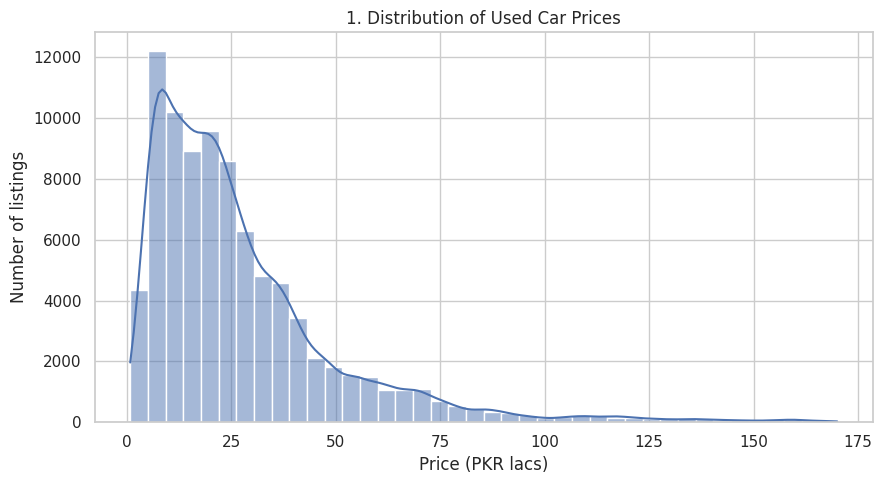

Saved: /content/drive/MyDrive/PriceSense/reports/figures/01_price_distribution.png


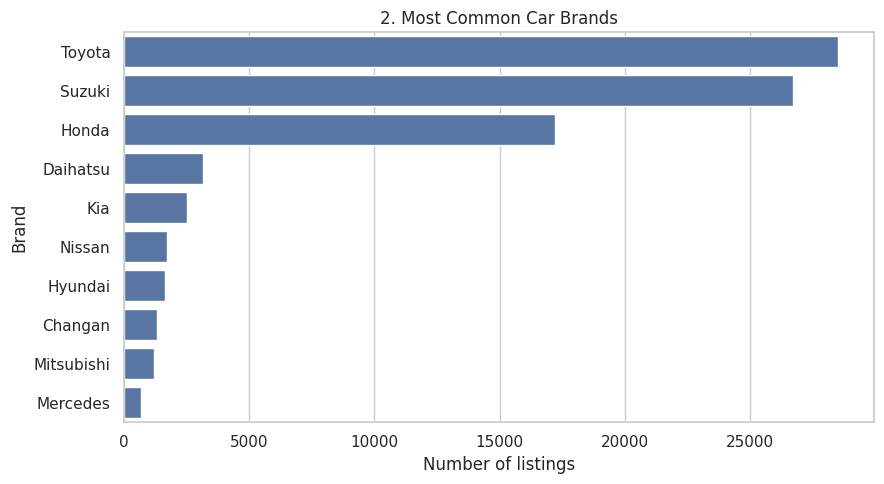

Saved: /content/drive/MyDrive/PriceSense/reports/figures/02_common_brands.png


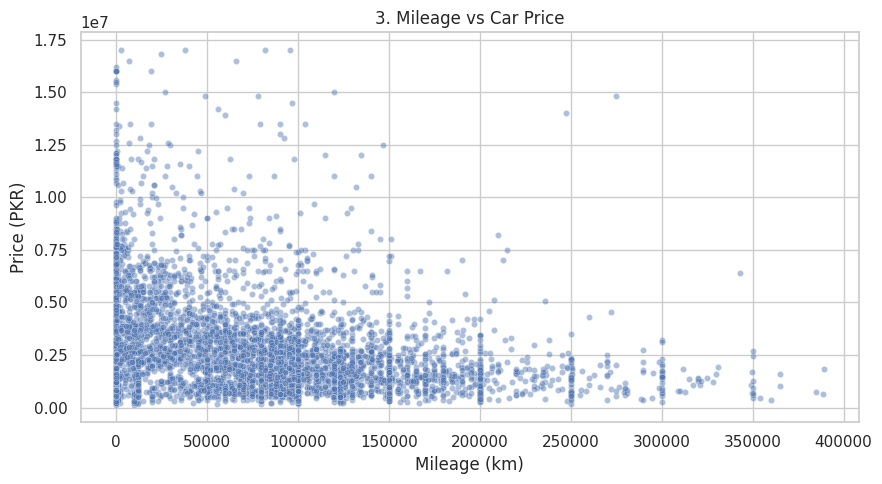

Saved: /content/drive/MyDrive/PriceSense/reports/figures/03_mileage_vs_price.png


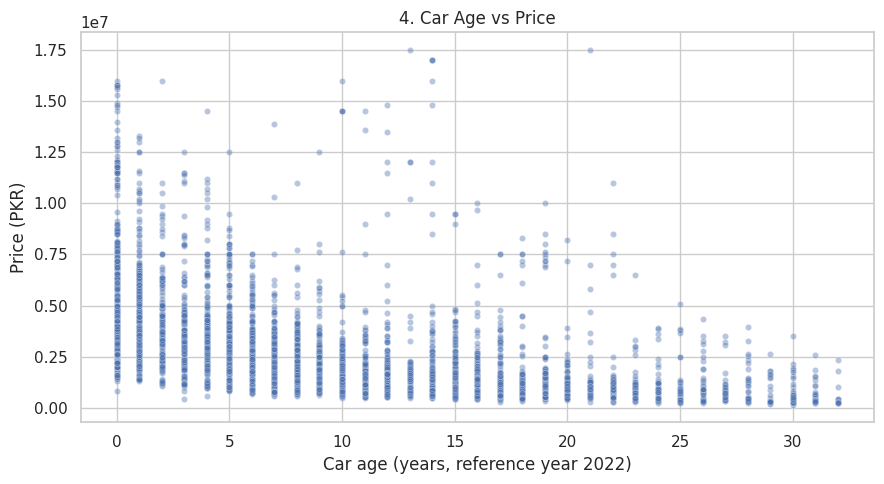

Saved: /content/drive/MyDrive/PriceSense/reports/figures/04_car_age_vs_price.png


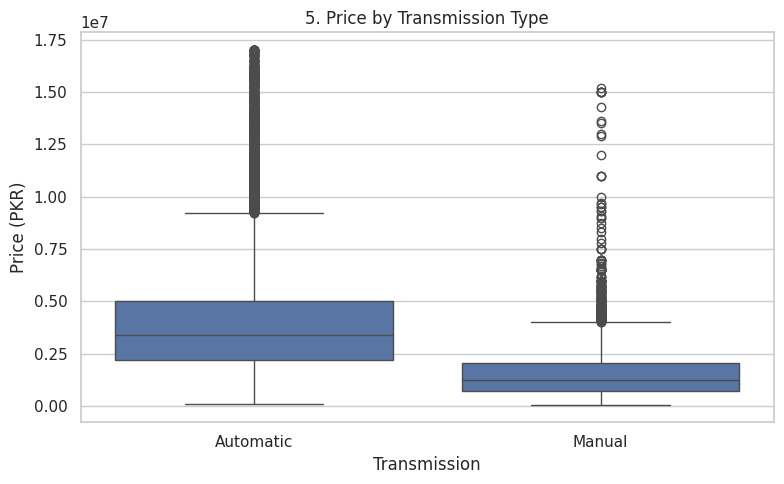

Saved: /content/drive/MyDrive/PriceSense/reports/figures/05_transmission_vs_price.png


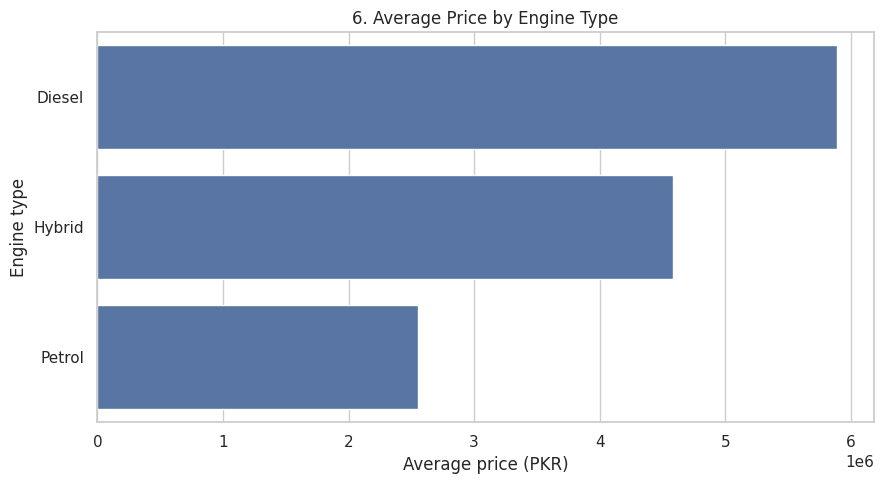

Saved: /content/drive/MyDrive/PriceSense/reports/figures/06_engine_type_vs_price.png


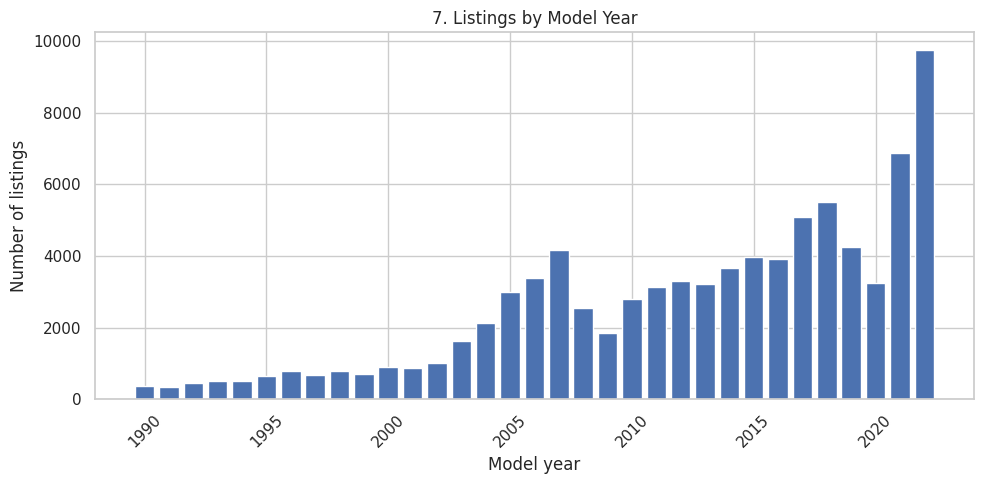

Saved: /content/drive/MyDrive/PriceSense/reports/figures/07_model_year_distribution.png


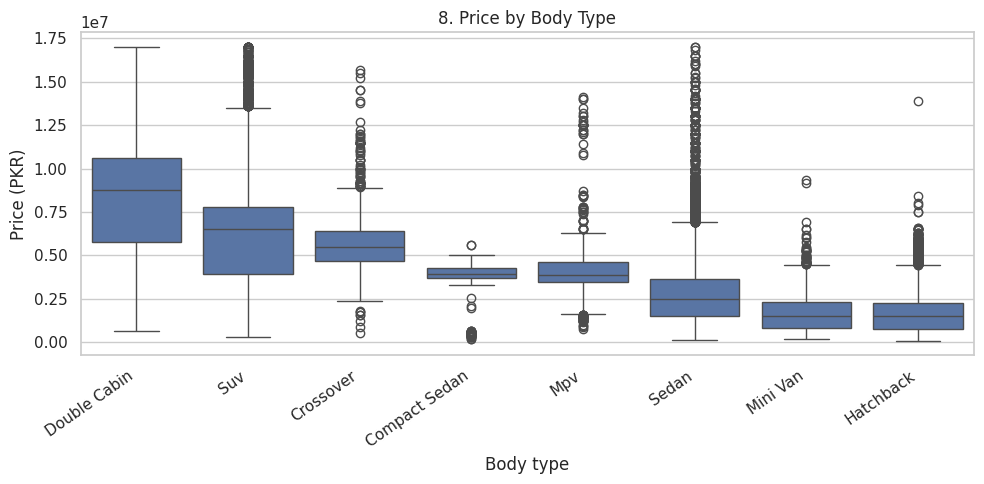

Saved: /content/drive/MyDrive/PriceSense/reports/figures/08_body_type_vs_price.png

ALL 8 EDA CHARTS CREATED
Insights report saved: /content/drive/MyDrive/PriceSense/reports/eda_insights.csv
Charts folder: /content/drive/MyDrive/PriceSense/reports/figures


,insight_number,title,finding
0,1,Car price distribution,"88,522 listings have usable prices. ..."
1,2,Most common car brands,The most frequently listed extracted...
2,3,Mileage and price,The Pearson correlation between mile...
3,4,Car age and price,The Pearson correlation between car ...
4,5,Automatic vs manual prices,Median prices by transmission (PKR):...
5,6,Engine type and price,Among the displayed common engine ty...
6,7,Model year distribution,"The most common model year is 2022, ..."
7,8,Body type and price,Among the displayed common body type...


In [16]:

import matplotlib.pyplot as plt
import seaborn as sns

CLEANED_PATH = os.path.join(
    PROJECT, "data", "processed", "pakwheels_cleaned.csv"
)
FIGURES_FOLDER = os.path.join(PROJECT, "reports", "figures")
os.makedirs(FIGURES_FOLDER, exist_ok=True)

clean_df = pd.read_csv(CLEANED_PATH, low_memory=False)

sns.set_theme(style="whitegrid")
insights = []

brand_pattern = (
    r"^(Toyota|Honda|Suzuki|Daihatsu|KIA|Hyundai|"
    r"Mitsubishi|Nissan|BMW|Mercedes|Audi|"
    r"Changan|MG|Proton|United|FAW|Prince|"
    r"DFSK|Isuzu|Chevrolet|Lexus|Subaru|"
    r"Volkswagen|Porsche|Haval|Peugeot|"
    r"Renault|JAC|GMC|Mazda|Ford|Jeep)\b"
)
clean_df["brand"] = (
    clean_df["title"].astype("string")
    .str.extract(brand_pattern, flags=0, expand=False)
    .str.title()
    .fillna("Other")
)

def save_chart(filename):
    path = os.path.join(FIGURES_FOLDER, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved:", path)

def add_insight(number, title, finding):
    insights.append({
        "insight_number": number,
        "title": title,
        "finding": finding
    })

prices = clean_df["price_pkr"].dropna()
price_limit = prices.quantile(0.99)
plot_prices = prices[prices <= price_limit]

plt.figure(figsize=(9, 5))
sns.histplot(plot_prices / 100000, bins=40, kde=True)
plt.title("1. Distribution of Used Car Prices")
plt.xlabel("Price (PKR lacs)")
plt.ylabel("Number of listings")
save_chart("01_price_distribution.png")

add_insight(
    1, "Car price distribution",
    f"{len(prices):,} listings have usable prices. "
    f"Median price is PKR {prices.median():,.0f}. "
    f"The chart displays prices up to the 99th percentile "
    f"(PKR {price_limit:,.0f}); higher prices remain in the dataset."
)

brand_counts = clean_df["brand"].value_counts()
top_brands = brand_counts.head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_brands.values, y=top_brands.index)
plt.title("2. Most Common Car Brands")
plt.xlabel("Number of listings")
plt.ylabel("Brand")
save_chart("02_common_brands.png")

add_insight(
    2, "Most common car brands",
    f"The most frequently listed extracted brand is "
    f"{top_brands.index[0]} ({top_brands.iloc[0]:,} listings). "
    f"Brand extraction uses the beginning of the title, so "
    f"unrecognized names are grouped under Other."
)

plot_df = clean_df.dropna(subset=["price_pkr", "mileage_km"])
plot_df = plot_df[
    (plot_df["price_pkr"] > 0) &
    (plot_df["mileage_km"] <= plot_df["mileage_km"].quantile(0.99)) &
    (plot_df["price_pkr"] <= plot_df["price_pkr"].quantile(0.99))
]

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=plot_df.sample(min(5000, len(plot_df)), random_state=42),
    x="mileage_km", y="price_pkr", alpha=0.45, s=20
)
plt.title("3. Mileage vs Car Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (PKR)")
save_chart("03_mileage_vs_price.png")

corr = clean_df[["mileage_km", "price_pkr"]].corr().iloc[0, 1]
add_insight(
    3, "Mileage and price",
    f"The Pearson correlation between mileage and price is "
    f"{corr:.3f}. This describes a linear association, not causation. "
    f"The plot excludes the top 1% of mileage and price only for readability."
)

age_df = clean_df.dropna(subset=["car_age", "price_pkr"])
age_df = age_df[(age_df["price_pkr"] > 0) & (age_df["price_pkr"] <= age_df["price_pkr"].quantile(0.99))]

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=age_df.sample(min(5000, len(age_df)), random_state=42),
    x="car_age", y="price_pkr", alpha=0.4, s=20
)
plt.title("4. Car Age vs Price")
plt.xlabel("Car age (years, reference year 2022)")
plt.ylabel("Price (PKR)")
save_chart("04_car_age_vs_price.png")

age_corr = clean_df[["car_age", "price_pkr"]].corr().iloc[0, 1]
add_insight(
    4, "Car age and price",
    f"The Pearson correlation between car age and price is "
    f"{age_corr:.3f}. Car age is calculated using 2022 as the "
    f"reference year because the listings are from 2022."
)

trans_df = clean_df.dropna(subset=["transmission", "price_pkr"]).copy()
trans_df["transmission"] = trans_df["transmission"].astype(str).str.strip().str.title()
trans_df = trans_df[
    trans_df["transmission"].isin(["Automatic", "Manual"]) &
    (trans_df["price_pkr"] <= trans_df["price_pkr"].quantile(0.99))
]

plt.figure(figsize=(8, 5))
sns.boxplot(data=trans_df, x="transmission", y="price_pkr")
plt.title("5. Price by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Price (PKR)")
save_chart("05_transmission_vs_price.png")

trans_medians = trans_df.groupby("transmission")["price_pkr"].median().to_dict()
add_insight(
    5, "Automatic vs manual prices",
    f"Median prices by transmission (PKR): {trans_medians}. "
    f"These are unadjusted comparisons; car brand, age and other features differ."
)

engine_df = clean_df.dropna(subset=["engine_type", "price_pkr"]).copy()
engine_df["engine_type"] = engine_df["engine_type"].astype(str).str.strip().str.title()
engine_df = engine_df[engine_df["price_pkr"] > 0]
top_engine_types = engine_df["engine_type"].value_counts().head(6).index
engine_df = engine_df[engine_df["engine_type"].isin(top_engine_types)]
engine_df = engine_df[engine_df["price_pkr"] <= engine_df["price_pkr"].quantile(0.99)]
engine_means = engine_df.groupby("engine_type")["price_pkr"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=engine_means.values, y=engine_means.index)
plt.title("6. Average Price by Engine Type")
plt.xlabel("Average price (PKR)")
plt.ylabel("Engine type")
save_chart("06_engine_type_vs_price.png")

add_insight(
    6, "Engine type and price",
    f"Among the displayed common engine types, "
    f"{engine_means.index[0]} has the highest average price "
    f"(PKR {engine_means.iloc[0]:,.0f}). This is an unadjusted comparison."
)

year_counts = clean_df["model_year_clean"].dropna().astype(int).value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(year_counts.index, year_counts.values)
plt.title("7. Listings by Model Year")
plt.xlabel("Model year")
plt.ylabel("Number of listings")
plt.xticks(rotation=45)
save_chart("07_model_year_distribution.png")

most_common_year = year_counts.idxmax()
add_insight(
    7, "Model year distribution",
    f"The most common model year is {most_common_year}, "
    f"with {year_counts.loc[most_common_year]:,} listings "
    f"having a valid model year."
)

body_df = clean_df.dropna(subset=["body_type", "price_pkr"]).copy()
body_df["body_type"] = body_df["body_type"].astype(str).str.strip().str.title()
body_df = body_df[body_df["price_pkr"] > 0]
top_body_types = body_df["body_type"].value_counts().head(8).index
body_df = body_df[body_df["body_type"].isin(top_body_types)]
body_df = body_df[body_df["price_pkr"] <= body_df["price_pkr"].quantile(0.99)]
body_medians = body_df.groupby("body_type")["price_pkr"].median().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.boxplot(data=body_df, x="body_type", y="price_pkr", order=body_medians.index)
plt.title("8. Price by Body Type")
plt.xlabel("Body type")
plt.ylabel("Price (PKR)")
plt.xticks(rotation=35, ha="right")
save_chart("08_body_type_vs_price.png")

add_insight(
    8, "Body type and price",
    f"Among the displayed common body types, "
    f"{body_medians.index[0]} has the highest median price "
    f"(PKR {body_medians.iloc[0]:,.0f}). Body types have different car mixes."
)

insights_path = os.path.join(PROJECT, "reports", "eda_insights.csv")
pd.DataFrame(insights).to_csv(insights_path, index=False)

print("\nALL 8 EDA CHARTS CREATED")
print("Insights report saved:", insights_path)
print("Charts folder:", FIGURES_FOLDER)
display(pd.DataFrame(insights))


***splitting***

In [17]:

from sklearn.model_selection import train_test_split

PROJECT_PATH = Path("/content/drive/MyDrive/PriceSense")

DATA_PATH = (
    PROJECT_PATH / "data" / "processed"
    / "pakwheels_cleaned.csv"
)

SPLIT_DIR = PROJECT_PATH / "data" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Original cleaned dataset:", df.shape)

df["price_pkr"] = pd.to_numeric(
    df["price_pkr"], errors="coerce"
)

df = df[
    df["price_pkr"].notna()
    & (df["price_pkr"] > 0)
].copy()

y = df["price_pkr"].copy()

drop_columns = [
    "price_pkr",
    "price",
    "description",
    "ad_url",
    "ad_last_updated",
    "price_pkr_iqr_outlier",
    "mileage_km_iqr_outlier",
    "any_iqr_outlier",
]

X = df.drop(
    columns=drop_columns,
    errors="ignore"
).copy()

duplicate_pairs = [
    ("model_year", "model_year_clean"),
    ("mileage", "mileage_km"),
    ("engine_capacity", "engine_capacity_cc"),
]

for raw_col, processed_col in duplicate_pairs:
    if raw_col in X.columns and processed_col in X.columns:
        X.drop(columns=[raw_col], inplace=True)

print("\nFeatures included in X:", len(X.columns))
print("Feature columns:")
print(X.columns.tolist())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

X_train.to_csv(SPLIT_DIR / "X_train.csv", index=False)
X_test.to_csv(SPLIT_DIR / "X_test.csv", index=False)

y_train.to_frame("price_pkr").to_csv(
    SPLIT_DIR / "y_train.csv", index=False
)
y_test.to_frame("price_pkr").to_csv(
    SPLIT_DIR / "y_test.csv", index=False
)

print("\nSPLIT COMPLETE")
print("-" * 40)
print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)
print("Training targets :", y_train.shape)
print("Testing targets  :", y_test.shape)

print(
    "\nTraining percentage:",
    round(len(X_train) / len(df) * 100, 2), "%"
)
print(
    "Testing percentage :",
    round(len(X_test) / len(df) * 100, 2), "%"
)

print("\nTrain/test split saved:", SPLIT_DIR)

Original cleaned dataset: (88522, 25)

Features included in X: 14
Feature columns:
['title', 'location', 'engine_type', 'transmission', 'registered_in', 'color', 'assembly', 'body_type', 'car_features', 'mileage_km', 'engine_capacity_cc', 'model_year_clean', 'car_age', 'mileage_per_year']

SPLIT COMPLETE
----------------------------------------
Training features: (70817, 14)
Testing features : (17705, 14)
Training targets : (70817,)
Testing targets  : (17705,)

Training percentage: 80.0 %
Testing percentage : 20.0 %

Train/test split saved: /content/drive/MyDrive/PriceSense/data/splits


***Model Training***

In [18]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_PATH = Path("/content/drive/MyDrive/PriceSense")
SPLIT_DIR = PROJECT_PATH / "data" / "splits"
MODEL_DIR = PROJECT_PATH / "models"
REPORT_DIR = PROJECT_PATH / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for folder in [MODEL_DIR, REPORT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DROP_COLUMNS = [
    "price", "price_pkr", "ad_url", "ad_last_updated", "description",
    "price_pkr_iqr_outlier", "mileage_km_iqr_outlier", "any_iqr_outlier",
    "model_year", "mileage", "engine_capacity",
]
TEXT_COLUMNS = ["title", "car_features"]


def load_split(prefix):
    X = pd.read_csv(SPLIT_DIR / f"X_{prefix}.csv", low_memory=False)
    y = pd.to_numeric(
        pd.read_csv(SPLIT_DIR / f"y_{prefix}.csv").iloc[:, 0], errors="raise"
    )
    X = X.drop(columns=DROP_COLUMNS, errors="ignore")
    for col in TEXT_COLUMNS:
        if col in X.columns:
            X[col] = X[col].fillna("").astype(str)
    return X, y


def build_pipeline(model_name, X_ref):
    if model_name == "Baseline (median)":
        return Pipeline([("model", DummyRegressor(strategy="median"))])

    text_cols = [c for c in TEXT_COLUMNS if c in X_ref.columns]
    num_cols = X_ref.select_dtypes(include="number").columns.tolist()
    cat_cols = [c for c in X_ref.columns if c not in num_cols and c not in text_cols]

    transformers = [
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_cols),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
        ]), cat_cols),
    ]
    for col, n_features in [("title", 1000), ("car_features", 300)]:
        if col in text_cols:
            transformers.append((f"text_{col}", TfidfVectorizer(
                max_features=n_features, min_df=3, ngram_range=(1, 2),
                sublinear_tf=True, dtype=np.float32), col))

    models = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(
            n_estimators=100, min_samples_leaf=2, max_features=0.3,
            random_state=42, n_jobs=2),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=200, max_depth=4, learning_rate=0.1,
            subsample=0.8, random_state=42),
    }
    return Pipeline([
        ("preprocessor", ColumnTransformer(transformers, remainder="drop")),
        ("model", models[model_name]),
    ])


def run_cv(model_name):
    X_train, y_train = load_split("train")
    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    print(f"\n{model_name}: 5-fold CV shuru...")
    res = cross_validate(
        build_pipeline(model_name, X_train), X_train, y_train, cv=cv,
        scoring={"mae": "neg_mean_absolute_error",
                 "rmse": "neg_root_mean_squared_error", "r2": "r2"},
        n_jobs=1, error_score="raise",
    )
    mae, rmse, r2 = -res["test_mae"], -res["test_rmse"], res["test_r2"]

    summary = {
        "model": model_name,
        "n_train_rows": int(len(X_train)),
        "feature_columns": list(X_train.columns),
        "MAE_mean": float(mae.mean()), "MAE_std": float(mae.std(ddof=1)),
        "RMSE_mean": float(rmse.mean()), "RMSE_std": float(rmse.std(ddof=1)),
        "R2_mean": float(r2.mean()), "R2_std": float(r2.std(ddof=1)),
    }
    slug = model_name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    with open(REPORT_DIR / f"cv_{slug}.json", "w") as f:
        json.dump(summary, f, indent=2)

    print(f"  MAE : PKR {mae.mean():,.0f} (+/- {mae.std(ddof=1):,.0f})")
    print(f"  RMSE: PKR {rmse.mean():,.0f}")
    print(f"  R2  : {r2.mean():.4f}")
    return summary

In [19]:
run_cv("Baseline (median)")


Baseline (median): 5-fold CV shuru...
  MAE : PKR 1,853,162 (+/- 29,164)
  RMSE: PKR 4,140,674
  R2  : -0.0495


{'model': 'Baseline (median)',
 'n_train_rows': 70817,
 'feature_columns': ['title',
  'location',
  'engine_type',
  'transmission',
  'registered_in',
  'color',
  'assembly',
  'body_type',
  'car_features',
  'mileage_km',
  'engine_capacity_cc',
  'model_year_clean',
  'car_age',
  'mileage_per_year'],
 'MAE_mean': 1853161.6020732753,
 'MAE_std': 29164.436969651088,
 'RMSE_mean': 4140673.586325097,
 'RMSE_std': 112741.48349943967,
 'R2_mean': -0.04953135648706573,
 'R2_std': 0.002050660877062952}

In [20]:

def run_cv(model_name):
    X_train, y_train = load_split("train")
    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    slug = model_name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    report_path = REPORT_DIR / f"cv_{slug}.json"

    if report_path.exists():
        with open(report_path, "r") as f:
            saved = json.load(f)

        if (
            saved.get("n_train_rows") == len(X_train)
            and saved.get("feature_columns") == list(X_train.columns)
        ):
            print(f"\n{model_name}: saved CV results loaded from Drive.")
            print(f"  MAE : PKR {saved['MAE_mean']:,.0f}")
            print(f"  RMSE: PKR {saved['RMSE_mean']:,.0f}")
            print(f"  R2  : {saved['R2_mean']:.4f}")
            return saved

    print(f"\n{model_name}: 5-fold CV shuru...")

    res = cross_validate(
        build_pipeline(model_name, X_train),
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=1,
        error_score="raise"
    )

    mae = -res["test_mae"]
    rmse = -res["test_rmse"]
    r2 = res["test_r2"]

    summary = {
        "model": model_name,
        "n_train_rows": int(len(X_train)),
        "feature_columns": list(X_train.columns),
        "MAE_mean": float(mae.mean()),
        "MAE_std": float(mae.std(ddof=1)),
        "RMSE_mean": float(rmse.mean()),
        "RMSE_std": float(rmse.std(ddof=1)),
        "R2_mean": float(r2.mean()),
        "R2_std": float(r2.std(ddof=1))
    }

    with open(report_path, "w") as f:
        json.dump(summary, f, indent=2)

    print(f"  MAE : PKR {mae.mean():,.0f}")
    print(f"  RMSE: PKR {rmse.mean():,.0f}")
    print(f"  R2  : {r2.mean():.4f}")
    print(f"  Saved: {report_path}")

    return summary


***1-Linear Regression***

In [21]:
run_cv("Linear Regression")


Linear Regression: saved CV results loaded from Drive.
  MAE : PKR 661,369
  RMSE: PKR 1,882,714
  R2  : 0.7826


{'model': 'Linear Regression',
 'n_train_rows': 70817,
 'feature_columns': ['title',
  'location',
  'engine_type',
  'transmission',
  'registered_in',
  'color',
  'assembly',
  'body_type',
  'car_features',
  'mileage_km',
  'engine_capacity_cc',
  'model_year_clean',
  'car_age',
  'mileage_per_year'],
 'MAE_mean': 661368.8055825889,
 'MAE_std': 10364.466826817341,
 'RMSE_mean': 1882714.4685996305,
 'RMSE_std': 115064.95442472826,
 'R2_mean': 0.7826114416204246,
 'R2_std': 0.022585456644218037}

***2-Gradient Boosting***

In [22]:
run_cv("Gradient Boosting")


Gradient Boosting: saved CV results loaded from Drive.
  MAE : PKR 437,337
  RMSE: PKR 1,270,771
  R2  : 0.9000


{'model': 'Gradient Boosting',
 'n_train_rows': 70817,
 'feature_columns': ['title',
  'location',
  'engine_type',
  'transmission',
  'registered_in',
  'color',
  'assembly',
  'body_type',
  'car_features',
  'mileage_km',
  'engine_capacity_cc',
  'model_year_clean',
  'car_age',
  'mileage_per_year'],
 'MAE_mean': 437336.526681705,
 'MAE_std': 1894.4050579916343,
 'RMSE_mean': 1270771.4515834393,
 'RMSE_std': 177067.73459974225,
 'R2_mean': 0.9000469849918261,
 'R2_std': 0.024792105932006526}

***3-Random Forest***

In [23]:
run_cv("Random Forest")


Random Forest: saved CV results loaded from Drive.
  MAE : PKR 287,511
  RMSE: PKR 1,225,712
  R2  : 0.9053


{'model': 'Random Forest',
 'n_train_rows': 70817,
 'feature_columns': ['title',
  'location',
  'engine_type',
  'transmission',
  'registered_in',
  'color',
  'assembly',
  'body_type',
  'car_features',
  'mileage_km',
  'engine_capacity_cc',
  'model_year_clean',
  'car_age',
  'mileage_per_year'],
 'MAE_mean': 287510.6156292517,
 'MAE_std': 10268.889403687774,
 'RMSE_mean': 1225712.0779324814,
 'RMSE_std': 262394.38904140715,
 'R2_mean': 0.905326788101745,
 'R2_std': 0.03736771785349796}

In [24]:

import json
import pandas as pd
from pathlib import Path

PROJECT_PATH = Path("/content/drive/MyDrive/PriceSense")
SPLIT_DIR = PROJECT_PATH / "data" / "splits"
REPORT_DIR = PROJECT_PATH / "reports"
MODEL_DIR = PROJECT_PATH / "models"

for folder in [REPORT_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MODELS = [
    "Baseline (median)",
    "Linear Regression",
    "Random Forest",
    "Gradient Boosting"
]

X_train, y_train = load_split("train")
rows = []

for name in MODELS:
    slug = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    path = REPORT_DIR / f"cv_{slug}.json"

    if not path.exists():
        raise FileNotFoundError(
            f"{name} ki CV report missing hai: {path}. Pehle CV run karein."
        )

    with open(path, "r") as f:
        s = json.load(f)

    if (
        s.get("n_train_rows") != len(X_train)
        or s.get("feature_columns") != list(X_train.columns)
    ):
        raise RuntimeError(
            f"{name} ki CV report current training features se match nahi karti. "
            "Is model ki CV dobara run karein."
        )

    rows.append({
        "model": name,
        "MAE_mean": s["MAE_mean"],
        "MAE_std": s["MAE_std"],
        "RMSE_mean": s["RMSE_mean"],
        "RMSE_std": s["RMSE_std"],
        "R2_mean": s["R2_mean"],
        "R2_std": s["R2_std"]
    })

comparison = pd.DataFrame(rows).sort_values(
    "MAE_mean"
).reset_index(drop=True)

comparison_path = REPORT_DIR / "model_comparison.csv"
comparison.to_csv(comparison_path, index=False)

comparison_json_path = REPORT_DIR / "model_comparison.json"
comparison.to_json(comparison_json_path, orient="records", indent=2)

real_models = comparison[
    comparison["model"] != "Baseline (median)"
]

best_row = real_models.iloc[0]
baseline_mae = comparison.loc[
    comparison["model"] == "Baseline (median)", "MAE_mean"
].iloc[0]

best_model_info = {
    "best_model": best_row["model"],
    "selection_metric": "5-fold cross-validation MAE",
    "best_cv_mae": float(best_row["MAE_mean"]),
    "best_cv_rmse": float(best_row["RMSE_mean"]),
    "best_cv_r2": float(best_row["R2_mean"]),
    "baseline_cv_mae": float(baseline_mae),
    "better_than_baseline": bool(
        best_row["MAE_mean"] < baseline_mae
    ),
    "n_train_rows": int(len(X_train)),
    "feature_columns": list(X_train.columns)
}

best_model_path = REPORT_DIR / "best_model.json"
with open(best_model_path, "w") as f:
    json.dump(best_model_info, f, indent=2)

print("Model comparison saved to Drive.")
display(comparison.round(3))

print("\nBest model by CV MAE:", best_row["model"])
print("CV MAE: PKR {:,.0f}".format(best_row["MAE_mean"]))
print("Baseline CV MAE: PKR {:,.0f}".format(baseline_mae))
print("Better than baseline:", best_model_info["better_than_baseline"])
print("\nSaved files:")
print(comparison_path)
print(comparison_json_path)
print(best_model_path)


Model comparison saved to Drive.


,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,Random Forest,287510.616,10268.889,1225712.078,262394.389,0.905,0.037
1,Gradient Boosting,437336.527,1894.405,1270771.452,177067.735,0.900,0.025
2,Linear Regression,661368.806,10364.467,1882714.469,115064.954,0.783,0.023
3,Baseline (median),1853161.602,29164.437,4140673.586,112741.483,-0.050,0.002



Best model by CV MAE: Random Forest
CV MAE: PKR 287,511
Baseline CV MAE: PKR 1,853,162
Better than baseline: True

Saved files:
/content/drive/MyDrive/PriceSense/reports/model_comparison.csv
/content/drive/MyDrive/PriceSense/reports/model_comparison.json
/content/drive/MyDrive/PriceSense/reports/best_model.json


In [26]:

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

PROJECT_PATH = Path("/content/drive/MyDrive/PriceSense")
REPORT_DIR = PROJECT_PATH / "reports"
MODEL_DIR = PROJECT_PATH / "models"
FIGURE_DIR = REPORT_DIR / "figures"

FINAL_PATH = MODEL_DIR / "pricesense_final_pipeline.joblib"
METRICS_PATH = REPORT_DIR / "final_test_metrics.json"
PREDICTIONS_PATH = REPORT_DIR / "final_test_predictions.csv"
COMPARISON_PATH = REPORT_DIR / "final_model_comparison.csv"
GRAPH_PATH = FIGURE_DIR / "final_actual_vs_predicted.png"
BEST_MODEL_PATH = REPORT_DIR / "best_model.json"

for folder in [REPORT_DIR, MODEL_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Missing file: {BEST_MODEL_PATH}. Run the model comparison cell first."
    )

best_name = json.loads(BEST_MODEL_PATH.read_text())["best_model"]

if FINAL_PATH.exists() and METRICS_PATH.exists():
    saved_metrics = json.loads(METRICS_PATH.read_text())

    if saved_metrics.get("best_model") == best_name:
        print("Saved final model found. Loading from Google Drive...")
        final_pipeline = joblib.load(FINAL_PATH)
        print("Existing model loaded. Training skipped.")

    else:
        print("Saved model does not match the selected model. Retraining...")
        final_pipeline = None
else:
    print("Saved final model or metrics missing. Training required.")
    final_pipeline = None

if final_pipeline is None:
    X_train, y_train = load_split("train")
    X_test, y_test = load_split("test")
    X_test = X_test.reindex(columns=X_train.columns)

    final_pipeline = build_pipeline(best_name, X_train)
    final_pipeline.fit(X_train, y_train)

    pred = np.clip(final_pipeline.predict(X_test), 0, None)

    mae = float(mean_absolute_error(y_test, pred))
    rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
    r2 = float(r2_score(y_test, pred))

    base = np.full(len(y_test), float(y_train.median()))
    b_mae = float(mean_absolute_error(y_test, base))
    b_rmse = float(np.sqrt(mean_squared_error(y_test, base)))
    b_r2 = float(r2_score(y_test, base))

    joblib.dump(final_pipeline, FINAL_PATH, compress=3)

    final_metrics = {
        "best_model": best_name,
        "evaluation": "test_set",
        "test_MAE_PKR": mae,
        "test_RMSE_PKR": rmse,
        "test_R2": r2,
        "baseline_MAE_PKR": b_mae,
        "baseline_RMSE_PKR": b_rmse,
        "baseline_R2": b_r2,
        "training_rows": int(len(X_train)),
        "testing_rows": int(len(X_test)),
        "feature_columns": list(X_train.columns)
    }

    METRICS_PATH.write_text(json.dumps(final_metrics, indent=2))

    pd.DataFrame({
        "actual_price_pkr": y_test.to_numpy(),
        "predicted_price_pkr": pred,
        "absolute_error_pkr": np.abs(y_test.to_numpy() - pred)
    }).to_csv(PREDICTIONS_PATH, index=False)

    pd.DataFrame({
        "MAE_PKR": [b_mae, mae],
        "RMSE_PKR": [b_rmse, rmse],
        "R2": [b_r2, r2]
    }, index=[
        "Baseline (train median)",
        f"{best_name} (final)"
    ]).to_csv(COMPARISON_PATH)

    plt.figure(figsize=(7, 6))
    plt.scatter(y_test, pred, alpha=0.25, s=10)
    limits = [
        float(min(y_test.min(), pred.min())),
        float(max(y_test.max(), pred.max()))
    ]
    plt.plot(limits, limits, "r--")
    plt.xlabel("Actual price (PKR)")
    plt.ylabel("Predicted price (PKR)")
    plt.title(f"{best_name}: Actual vs Predicted (Test Set)")
    plt.tight_layout()
    plt.savefig(GRAPH_PATH, dpi=150, bbox_inches="tight")
    plt.close()

    print("Training and evaluation completed.")
    print("Test MAE: PKR {:,.0f}".format(mae))
    print("Test RMSE: PKR {:,.0f}".format(rmse))
    print("Test R2: {:.4f}".format(r2))

else:
    print("Previously saved final metrics:")
    for key in ["test_MAE_PKR", "test_RMSE_PKR", "test_R2"]:
        print(f"{key}: {saved_metrics[key]}")

print("\nFiles in Google Drive:")
for path in [
    FINAL_PATH,
    METRICS_PATH,
    PREDICTIONS_PATH,
    COMPARISON_PATH,
    GRAPH_PATH
]:
    print(f"{'SAVED' if path.exists() else 'MISSING'}: {path}")


Saved final model found. Loading from Google Drive...
Existing model loaded. Training skipped.
Previously saved final metrics:
test_MAE_PKR: 285144.9497991904
test_RMSE_PKR: 1312348.5681718308
test_R2: 0.8959476691703262

Files in Google Drive:
SAVED: /content/drive/MyDrive/PriceSense/models/pricesense_final_pipeline.joblib
SAVED: /content/drive/MyDrive/PriceSense/reports/final_test_metrics.json
SAVED: /content/drive/MyDrive/PriceSense/reports/final_test_predictions.csv
SAVED: /content/drive/MyDrive/PriceSense/reports/final_model_comparison.csv
SAVED: /content/drive/MyDrive/PriceSense/reports/figures/final_actual_vs_predicted.png
